# Homework 7: GANs and FashionMNIST autoencoders
**SID4 = 6812 | SEED = 6812 | SLICE = 812 | HP_ID = 2 | CLS_A = 2 | CLS_B = 9**

Run every cell in order. This notebook contains the complete PyTorch implementation and trains both models for 20 epochs. Required dependencies are listed in requirements.txt. HW7.md contains the written answers and interpretation. Outputs, checkpoints, and timestamped logs are saved automatically. Only SEED is used; HW7 provides no HP_ID mapping.


In [1]:
from pathlib import Path
__file__ = str(Path.cwd() / "hw7.py")
"""Homework 7: reproducible FC-AE and VAE training on FashionMNIST."""
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
import argparse
import csv
import json
import logging
import platform
import random
import time
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
import torchvision
from torchvision.datasets import FashionMNIST

SEED = 6812
ROOT = Path(__file__).resolve().parent
CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal",
           "Shirt", "Sneaker", "Bag", "Ankle boot"]


def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


class FCAE(nn.Module):
    def __init__(self, latent=32):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(784, 256), nn.ReLU(),
                                     nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, latent))
        self.decoder = nn.Sequential(nn.Linear(latent, 128), nn.ReLU(),
                                     nn.Linear(128, 256), nn.ReLU(), nn.Linear(256, 784))

    def forward(self, x):
        return self.decoder(self.encoder(x)), None, None


class VAE(nn.Module):
    def __init__(self, latent=32):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 128), nn.ReLU())
        self.mu = nn.Linear(128, latent)
        self.logvar = nn.Linear(128, latent)
        self.decoder = nn.Sequential(nn.Linear(latent, 128), nn.ReLU(),
                                     nn.Linear(128, 256), nn.ReLU(), nn.Linear(256, 784))

    def forward(self, x, sample=True):
        h = self.encoder(x)
        mu, logvar = self.mu(h), self.logvar(h)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu) if sample else mu
        return self.decoder(z), mu, logvar


def losses(logits, x, mu, logvar):
    reconstruction = F.binary_cross_entropy_with_logits(logits, x, reduction="none").sum(1)
    kl = torch.zeros_like(reconstruction) if mu is None else (
        -0.5 * (1 + logvar - mu.square() - logvar.exp()).sum(1))
    return reconstruction, kl


@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()
    # A fixed seed makes validation sampling repeatable across epochs.
    with torch.random.fork_rng(devices=[device.index or 0] if device.type == "cuda" else []):
        torch.manual_seed(SEED)
        sums = np.zeros(5, dtype=np.float64)
        class_sums = np.zeros(10)
        class_counts = np.zeros(10, dtype=np.int64)
        count = 0
        for x, y in loader:
            x = x.to(device)
            logits, mu, logvar = model(x)
            rec, kl = losses(logits, x, mu, logvar)
            deterministic_logits = model.decoder(mu) if mu is not None else logits
            pred = deterministic_logits.sigmoid()
            mse = (pred - x).square().mean(1)
            mae = (pred - x).abs().mean(1)
            bce = F.binary_cross_entropy_with_logits(deterministic_logits, x, reduction="none").mean(1)
            sums += np.array([v.sum().item() for v in (rec, kl, mse, mae, bce)])
            np.add.at(class_sums, y.numpy(), mse.cpu().numpy())
            np.add.at(class_counts, y.numpy(), 1)
            count += len(x)
        # Keep metadata as Python scalars so weights_only checkpoint loading works.
        rec, kl, mse, mae, bce = map(float, sums / count)
        return dict(objective=rec + kl, reconstruction_bce_sum=rec, kl=kl,
                    mse=mse, mae=mae, bce_per_pixel=bce,
                    per_class_mse=dict(zip(CLASSES, (class_sums / class_counts).tolist())))


def train(name, model, train_loader, val_loader, device, args, out):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=args.lr)
    history, best = [], float("inf")
    for epoch in range(1, args.epochs + 1):
        start = time.perf_counter()
        model.train()
        totals = np.zeros(2)
        n = 0
        for x, _ in train_loader:
            x = x.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits, mu, logvar = model(x)
            rec, kl = losses(logits, x, mu, logvar)
            loss = (rec + kl).mean()
            if not torch.isfinite(loss):
                raise RuntimeError(f"Non-finite {name} loss at epoch {epoch}")
            loss.backward()
            optimizer.step()
            totals += [rec.detach().sum().item(), kl.detach().sum().item()]
            n += len(x)
        val = evaluate(model, val_loader, device)
        row = dict(epoch=epoch, train_reconstruction=totals[0] / n, train_kl=totals[1] / n,
                   train_objective=totals.sum() / n, val_objective=val["objective"],
                   val_mse=val["mse"], seconds=time.perf_counter() - start)
        history.append(row)
        if val["objective"] < best:
            best = val["objective"]
            torch.save(dict(model=model.state_dict(), optimizer=optimizer.state_dict(),
                            epoch=epoch, config=vars(args), seed=SEED, validation=val), out / f"{name}_best.pt")
        logging.info("%s epoch %02d/%d train=%.4f val=%.4f val_MSE=%.6f %.1fs",
                     name, epoch, args.epochs, row["train_objective"], val["objective"], val["mse"], row["seconds"])
    with (out / f"{name}_history.csv").open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=history[0].keys())
        writer.writeheader()
        writer.writerows(history)
    checkpoint = torch.load(out / f"{name}_best.pt", map_location=device, weights_only=True)
    model.load_state_dict(checkpoint["model"])
    return model, history, checkpoint["epoch"]


@torch.no_grad()
def figures(models, histories, test_x, test_y, device, out):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, (name, history) in zip(axes, histories.items()):
        ax.plot([r["epoch"] for r in history], [r["train_objective"] for r in history], label="Train")
        ax.plot([r["epoch"] for r in history], [r["val_objective"] for r in history], label="Validation")
        ax.set(title=name, xlabel="Epoch", ylabel="Objective per image (nats)")
        ax.legend()
    fig.tight_layout()
    fig.savefig(out / "training_curves.png", dpi=160)
    plt.close(fig)
    indices = [torch.where(test_y == i)[0][0].item() for i in range(10)]
    x = test_x[indices].to(device)
    rows = [x.cpu(), models["fc_ae"](x)[0].sigmoid().cpu(), models["vae"](x, sample=False)[0].sigmoid().cpu()]
    fig, axes = plt.subplots(3, 10, figsize=(15, 5))
    for i, row in enumerate(rows):
        for j, img in enumerate(row):
            axes[i, j].imshow(img.reshape(28, 28), cmap="gray", vmin=0, vmax=1)
            axes[i, j].set_xticks([])
            axes[i, j].set_yticks([])
            if i == 0:
                axes[i, j].set_title(CLASSES[j], fontsize=9)
        axes[i, 0].set_ylabel(["Original", "FC-AE", "VAE (mean)"][i])
    fig.tight_layout()
    fig.savefig(out / "reconstructions.png", dpi=160)
    plt.close(fig)
    seed_all(SEED)
    samples = models["vae"].decoder(torch.randn(32, models["vae"].mu.out_features, device=device)).sigmoid().cpu()
    fig, axes = plt.subplots(4, 8, figsize=(8, 4))
    for ax, img in zip(axes.flat, samples):
        ax.imshow(img.reshape(28, 28), cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
    fig.suptitle("VAE samples from N(0, I); no input image")
    fig.tight_layout()
    fig.savefig(out / "vae_samples.png", dpi=160)
    plt.close(fig)


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--epochs", type=int, default=20)
    parser.add_argument("--batch-size", type=int, default=256)
    parser.add_argument("--latent", type=int, default=32)
    parser.add_argument("--lr", type=float, default=1e-3)
    args = parser.parse_args()
    if min(args.epochs, args.batch_size, args.latent, args.lr) <= 0:
        parser.error("All training parameters must be positive")
    out = ROOT / "hw7_outputs"
    out.mkdir(exist_ok=True)
    logging.basicConfig(level=logging.INFO, format="%(asctime)s UTC %(message)s",
                        handlers=[logging.FileHandler(out / "run.log", mode="w", encoding="utf-8"),
                                  logging.FileHandler(ROOT / "RUN_LOG.txt", mode="a", encoding="utf-8"),
                                  logging.StreamHandler()], force=True)
    logging.Formatter.converter = time.gmtime
    torch.set_num_threads(4)
    torch.use_deterministic_algorithms(True)
    torch.backends.cudnn.benchmark = False
    seed_all(SEED)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    metadata = dict(seed=SEED, config=vars(args), python=platform.python_version(),
                    torch=torch.__version__, torchvision=torchvision.__version__,
                    device=torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")
    logging.info("HW7 configuration: %s", metadata)
    data = ROOT / "hw7_data"
    # Official upstream HTTPS mirror, with torchvision's built-in MD5 validation.
    FashionMNIST.mirrors = ["https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"]
    full = FashionMNIST(data, train=True, download=True)
    test = FashionMNIST(data, train=False, download=True)
    x = full.data.float().reshape(-1, 784) / 255.0
    test_x = test.data.float().reshape(-1, 784) / 255.0
    order = torch.randperm(len(x), generator=torch.Generator().manual_seed(SEED))
    train_ids, val_ids = order[:55000], order[55000:]
    np.savez(out / "split_indices.npz", train=train_ids.numpy(), validation=val_ids.numpy())
    val_loader = DataLoader(TensorDataset(x[val_ids], full.targets[val_ids]), batch_size=args.batch_size)
    test_loader = DataLoader(TensorDataset(test_x, test.targets), batch_size=args.batch_size)
    models, histories, results = {}, {}, {}
    for name, cls in [("fc_ae", FCAE), ("vae", VAE)]:
        seed_all(SEED)
        train_loader = DataLoader(TensorDataset(x[train_ids], full.targets[train_ids]),
                                  batch_size=args.batch_size, shuffle=True,
                                  generator=torch.Generator().manual_seed(SEED), num_workers=0)
        model, history, epoch = train(name, cls(args.latent), train_loader, val_loader, device, args, out)
        metrics = evaluate(model, test_loader, device)
        metrics.update(best_epoch=epoch, parameters=sum(p.numel() for p in model.parameters()))
        logging.info("%s TEST %s", name, metrics)
        models[name], histories[name], results[name] = model, history, metrics
    metadata.update(train_size=55000, validation_size=5000, test_size=10000, results=results)
    (out / "metrics.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
    figures(models, histories, test_x, test.targets, device, out)
    logging.info("Completed both models, test evaluation, and figures.")



In [2]:
import sys
saved_argv = sys.argv.copy()
try:
    sys.argv = ["hw7.py"]
    main()
finally:
    sys.argv = saved_argv


2026-10-20 20:46:35,532 UTC HW7 configuration: {'seed': 6812, 'config': {'epochs': 20, 'batch_size': 256, 'latent': 32, 'lr': 0.001}, 'python': '3.13.7', 'torch': '2.6.0+cu124', 'torchvision': '0.21.0+cu124', 'device': 'NVIDIA GeForce GTX 1650'}


2026-10-20 20:46:39,695 UTC fc_ae epoch 01/20 train=304.4547 val=256.6785 val_MSE=0.029515 3.5s


2026-10-20 20:46:42,079 UTC fc_ae epoch 02/20 train=247.0152 val=241.3836 val_MSE=0.022494 2.4s


2026-10-20 20:46:44,408 UTC fc_ae epoch 03/20 train=239.2935 val=236.8747 val_MSE=0.020444 2.3s


2026-10-20 20:46:46,983 UTC fc_ae epoch 04/20 train=235.2695 val=233.0168 val_MSE=0.018739 2.6s


...

2026-10-20 20:48:20,229 UTC vae epoch 18/20 train=241.4842 val=241.3449 val_MSE=0.015592 2.9s


2026-10-20 20:48:23,496 UTC vae epoch 19/20 train=241.2447 val=241.0765 val_MSE=0.015471 3.2s


2026-10-20 20:48:26,296 UTC vae epoch 20/20 train=241.0315 val=241.0426 val_MSE=0.015485 2.8s


2026-10-20 20:48:26,706 UTC vae TEST {'objective': 242.94652835235595, 'reconstruction_bce_sum': 230.06247458496094, 'kl': 12.88405376739502, 'mse': 0.015510372185707092, 'mae': 0.06558850911855697, 'bce_per_pixel': 0.28915043277740476, 'per_class_mse': {'T-shirt/top': 0.014617695028660819, 'Trouser': 0.008367975360248237, 'Pullover': 0.014936285953968764, 'Dress': 0.01451853522984311, 'Coat': 0.013873751778155564, 'Sandal': 0.023258242725627497, 'Shirt': 0.015062118251575158, 'Sneaker': 0.01174121521692723, 'Bag': 0.023113840768579395, 'Ankle boot': 0.015614061824511737}, 'best_epoch': 20, 'parameters': 480848}


2026-10-20 20:48:28,998 UTC Completed both models, test evaluation, and figures.


{
  "seed": 6812,
  "config": {
    "epochs": 20,
    "batch_size": 256,
    "latent": 32,
    "lr": 0.001
  },
  "python": "3.13.7",
  "torch": "2.6.0+cu124",
  "torchvision": "0.21.0+cu124",
  "device": "NVIDIA GeForce GTX 1650",
  "train_size": 55000,
  "validation_size": 5000,
  "test_size": 10000,
  "results": {
    "fc_ae": {
      "objective": 219.44462436523438,
      "reconstruction_bce_sum": 219.44462436523438,
      "kl": 0.0,
      "mse": 0.012105227378010749,
      "mae": 0.05725825964212418,
      "bce_per_pixel": 0.2799038480758667,
      "per_class_mse": {
        "T-shirt/top": 0.011067152056726627,
        "Trouser": 0.006064992129453458,
        "Pullover": 0.011517050681402907,
        "Dress": 0.011140341432997957,
        "Coat": 0.010726251875748858,
        "Sandal": 0.018371876580640673,
        "Shirt": 0.012063230565283448,
        "Sneaker": 0.00890656192705501,
        "Bag": 0.019209356869570912,
        "Ankle boot": 0.011985459582880139
      },
      "b

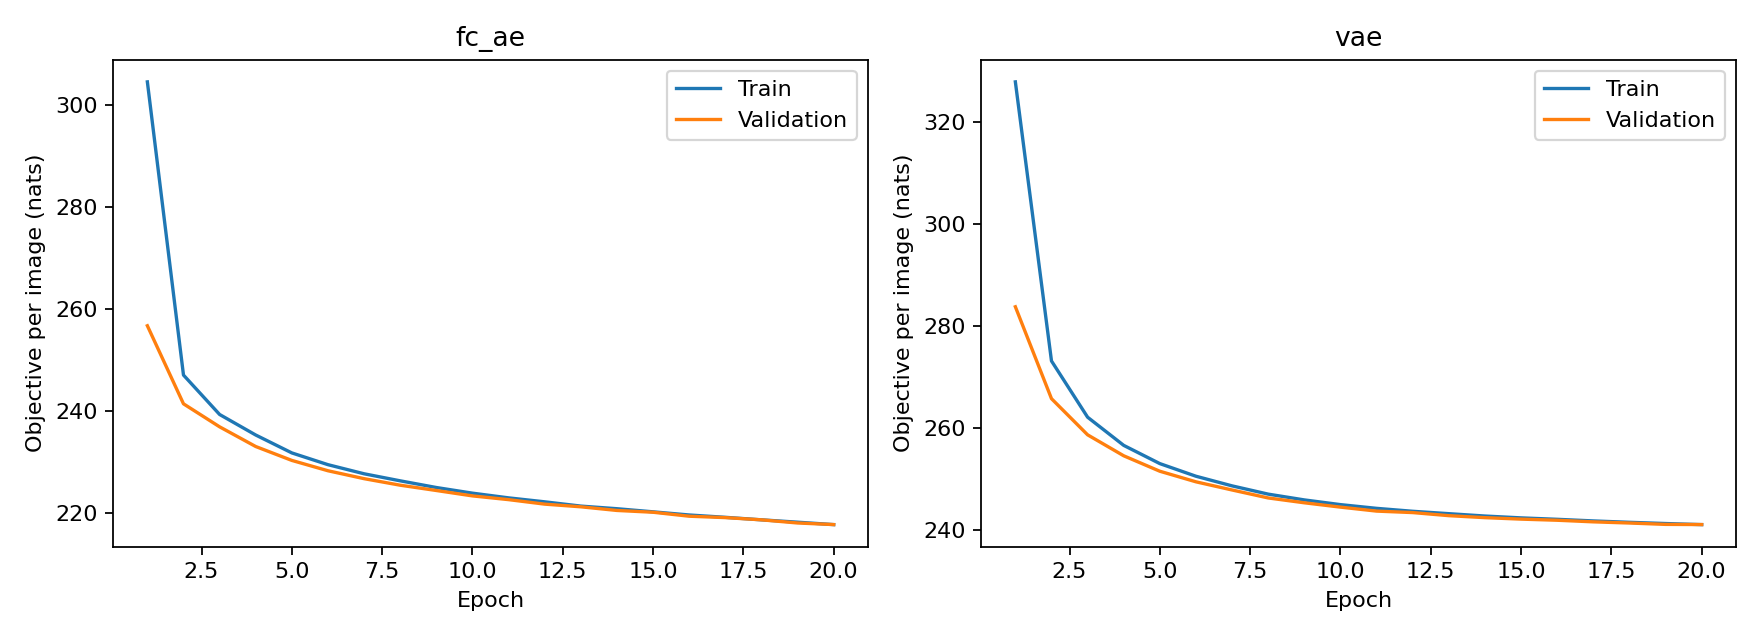

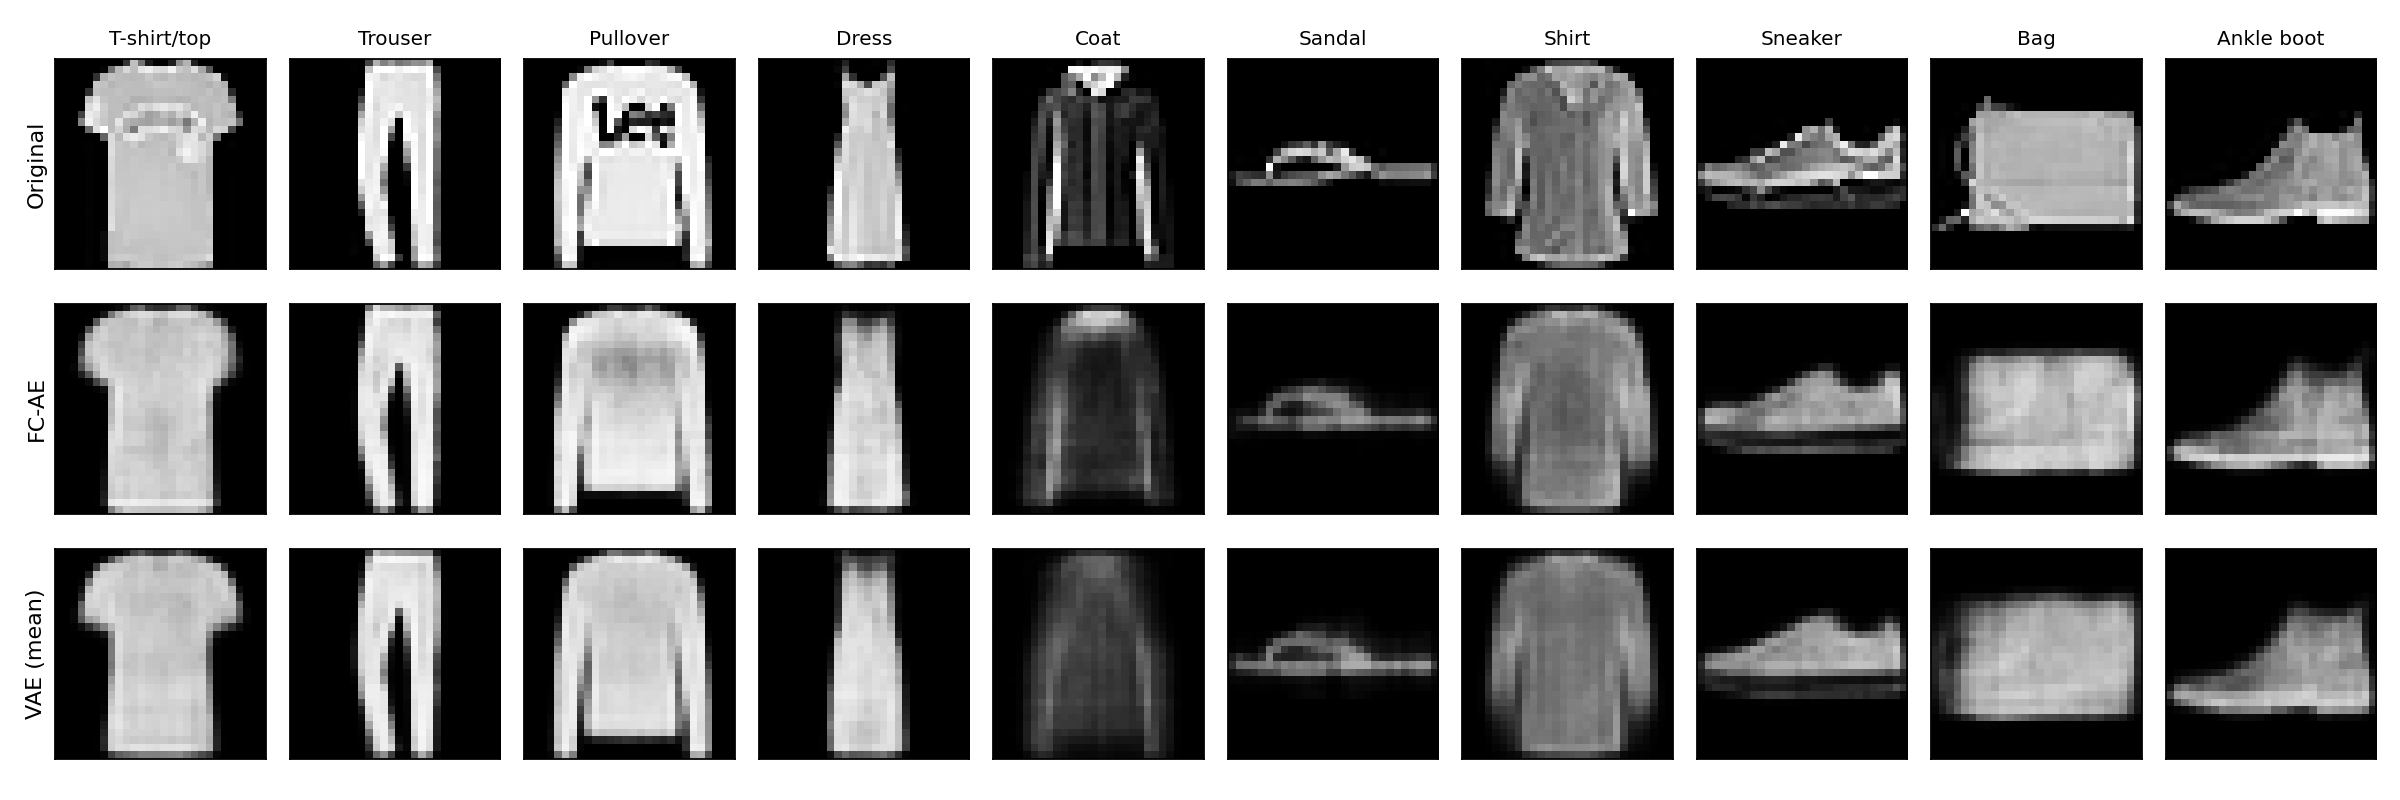

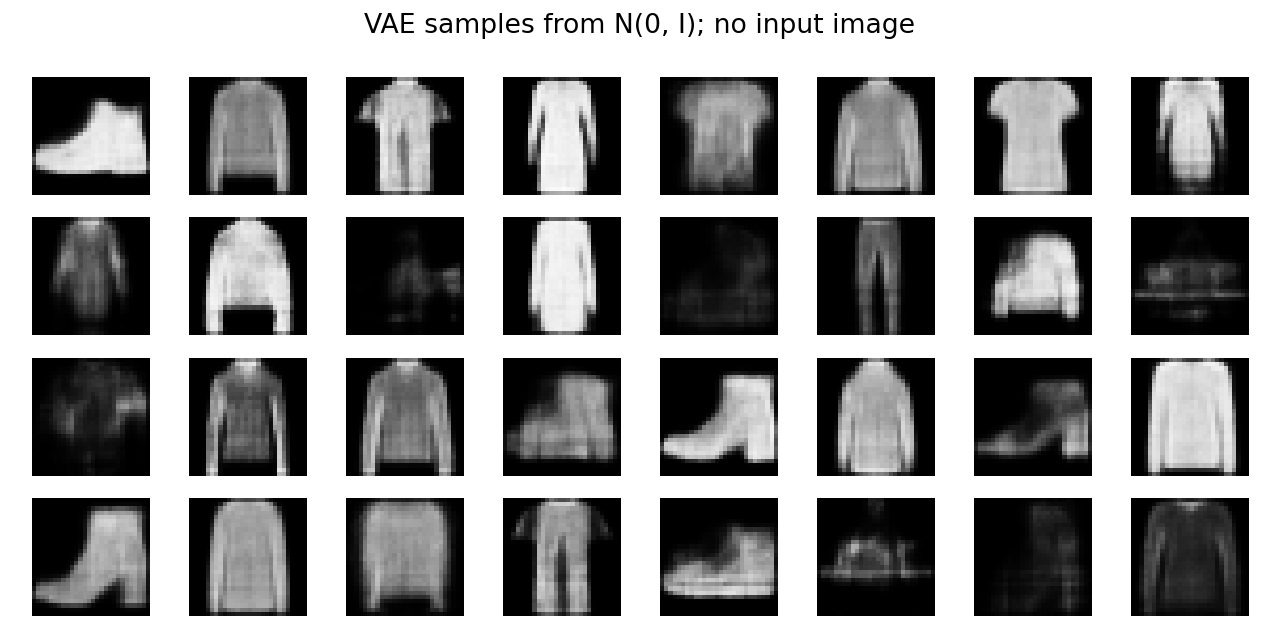

In [3]:
from IPython.display import display, Image
print((ROOT / "hw7_outputs" / "metrics.json").read_text())
for filename in ["training_curves.png", "reconstructions.png", "vae_samples.png"]:
    display(Image(filename=str(ROOT / "hw7_outputs" / filename)))
